# K-Means và tuning — Huy (tuần 3A)

Đồ án đề tài 15, nhóm 4 người — Trường Đại học Sài Gòn, GV Đỗ Như Tài. Dữ liệu: UCI Online Retail (01/12/2010–09/12/2011).

**Mục tiêu tuần 3A:** (1) tuning K-Means trên hai bộ đặc trưng `RFM` và `RFM_PLUS` (k = 2–10, init `k-means++` và `random`, `n_init` chọn ở mục 2, `random_state = SEED`) và ghi `reports/tables/tuning_kmeans.csv` đúng schema chung; (2) đọc Elbow, Silhouette, Davies–Bouldin, Calinski–Harabasz theo k để chọn k; (3) so `RFM` với `RFM_PLUS`; (4) chọn top 3 cấu hình theo chỉ số nội tại và lưu nhãn; (5) phân tích sơ bộ kích thước cụm, cụm quá nhỏ và ảnh hưởng của ngoại lệ lên tâm cụm.

**Phạm vi:** notebook này **không đọc** `future_outcome.csv` và không làm đánh giá ngoài (RQ3). Hierarchical và DBSCAN là phần việc song song, không nằm ở đây.

**Kiểm soát data leakage và so sánh công bằng:**

- Đầu vào chỉ là `features_obs.csv` và scaler đã fit ở tuần 2 trên giai đoạn quan sát (trước `CUTOFF`). Mục 1 kiểm tra bằng `assert`, gồm việc mã nguồn K-Means không đọc bất kỳ file nào trong `data/processed/`.
- `n_init`, `k`, `init` và top 3 đều chọn bằng chỉ số nội tại, inertia và độ ổn định giữa các seed; không có nhãn kiểm chứng nào tham gia.
- Mọi cấu hình dùng cùng ma trận đã scale, cùng hàm metric `baseline.internal_metrics` (tính trên toàn bộ điểm, không lấy mẫu), cùng `SEED` và cùng schema `TUNING_SCHEMA` với baseline và các mô hình khác, nên bảng tuning gộp lại so sánh được.

In [1]:
from pathlib import Path
import inspect
import json
import sys

# Hỗ trợ chạy từ thư mục gốc hoặc notebooks/.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from src.config import (SEED, RFM, RFM_PLUS, FEATURE_SETS, DATA_PROCESSED, TABLES_DIR, FIGURES_DIR,
                        TUNING_SCHEMA, KMEANS_K_RANGE, KMEANS_INITS, KMEANS_N_INIT)
from src import features as ft, clustering as cl, viz_kmeans as vk

np.random.seed(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
for d in (TABLES_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("ROOT =", ROOT, "| SEED =", SEED, "| k =", KMEANS_K_RANGE[0], "-", KMEANS_K_RANGE[-1],
      "| init =", KMEANS_INITS, "| n_init =", KMEANS_N_INIT)

ROOT = /home/claude/machine_learning/DoAn | SEED = 42 | k = 2 - 10 | init = ('k-means++', 'random') | n_init = 200


## 1. Nạp đặc trưng đã scale và kiểm tra đầu vào

Không fit lại scaler ở đây: `transform_features(..., fit_scaler=False)` nạp scaler tuần 2 (đã fit trên đúng tập khách giai đoạn quan sát) để mọi thành viên làm việc trên **cùng một ma trận**. Fit lại ở mỗi notebook vẫn không rò rỉ nhưng dễ tạo ra những ma trận lệch nhau chút ít và làm so sánh giữa các mô hình mất công bằng.

Quyết định log1p đã chốt ở tuần 2 theo quy tắc "skew gốc > 1 **và** log1p giảm |skew| ít nhất một nửa", không áp dụng máy móc: bảng dưới nhắc lại biến nào được log1p. Biến không được log1p (`Recency`, `AvgInterPurchaseDays`, `CancelRate`) chỉ được `StandardScaler`.

In [2]:
feats = pd.read_csv(DATA_PROCESSED / "features_obs.csv", index_col="CustomerID")
assert set(RFM_PLUS) <= set(feats.columns) and feats.notna().all().all()
assert not {"FutureSpend", "Returned"} & set(feats.columns), "nhãn kiểm chứng lẫn vào đặc trưng"

x_by_set = {name: ft.transform_features(feats, cols, fit_scaler=False) for name, cols in FEATURE_SETS.items()}
for name, x in x_by_set.items():
    # scaler đã fit trên đúng tập khách này: mỗi cột trung bình 0, độ lệch chuẩn 1
    assert x.index.equals(feats.index) and list(x.columns) == FEATURE_SETS[name]
    assert np.allclose(x.mean(), 0, atol=1e-8) and np.allclose(x.std(ddof=0), 1, atol=1e-8)
    assert ft.load_scaler_bundle(FEATURE_SETS[name])["scaler"].n_samples_seen_ == len(feats)

# Mã nguồn K-Means/hình không đọc file nào trong data/processed (nơi có future_outcome.csv)
for mod in (cl, vk):
    code = inspect.getsource(mod)
    assert "DATA_PROCESSED" not in code and "read_csv" not in code, f"{mod.__name__} đọc dữ liệu ngoài"

print(f"{len(feats):,} khách, {len(RFM)} đặc trưng RFM, {len(RFM_PLUS)} đặc trưng RFM_PLUS; đầu vào hợp lệ.")
print(f"Khách chỉ mua một lần (AvgInterPurchaseDays là giá trị điền): {feats.SinglePurchase.mean():.1%}")
display(ft.skewness_report(feats, RFM_PLUS))

3,360 khách, 3 đặc trưng RFM, 7 đặc trưng RFM_PLUS; đầu vào hợp lệ.
Khách chỉ mua một lần (AvgInterPurchaseDays là giá trị điền): 40.8%


,skew_before,skew_log1p,log1p
feature,,,
Recency,0.764,-0.846,False
Frequency,9.155,1.378,True
Monetary,16.296,0.407,True
AvgOrderValue,46.699,0.166,True
NUniqueProducts,6.194,-0.217,True
AvgInterPurchaseDays,0.155,-1.106,False
CancelRate,1.443,1.300,False


## 2. Chọn `n_init`: bằng chứng, không đoán

K-Means chỉ hội tụ về cực tiểu **cục bộ** nên kết quả phụ thuộc khởi tạo. `n_init` là số lần khởi tạo độc lập, giữ lần có inertia nhỏ nhất. Cần đủ lớn để kết quả không còn phụ thuộc `random_state`, nhưng không lớn quá mức cần thiết.

Phép kiểm tra: với `n_init` ∈ {1, 5, 10, 50, 200}, chạy 20 seed khác nhau và đo (a) độ trải của inertia qua các seed, (b) **ARI** giữa nghiệm của từng seed và nghiệm tốt nhất tìm được. Cần cả ARI vì inertia gần bằng nhau chưa chắc là cùng một phân hoạch. Thử ở k = 4 (cấu hình nhiều khả năng được chọn) và k = 10 (khó nhất). Phép kiểm tra chỉ dùng chỉ số nội tại.

In [3]:
parts = []
for name, x in x_by_set.items():
    for k in (4, 10):
        r = cl.kmeans_ninit_check(x, k, n_inits=(1, 5, 10, 50, KMEANS_N_INIT)).reset_index()
        r.insert(0, "k", k)
        r.insert(0, "feature_set", name)
        parts.append(r)
ninit = pd.concat(parts, ignore_index=True)
with pd.option_context("display.float_format", "{:.5f}".format):
    display(ninit)

,feature_set,k,n_init,inertia_min,inertia_max,rel_spread,ari_min,ari_median
0,RFM,4,1,2719.23539,2719.92883,0.00026,0.95640,1.00000
1,RFM,4,5,2719.23539,2719.28471,0.00002,0.99910,1.00000
2,RFM,4,10,2719.23539,2719.28471,0.00002,0.99910,1.00000
3,RFM,4,50,2719.23539,2719.23539,0.00000,1.00000,1.00000
4,RFM,4,200,2719.23539,2719.23539,0.00000,1.00000,1.00000
5,RFM,10,1,1438.89241,1478.72149,0.02768,0.42590,0.63459
6,RFM,10,5,1438.80482,1451.60135,0.00889,0.57304,0.88762
7,RFM,10,10,1438.80482,1441.35680,0.00177,0.73003,0.93677
8,RFM,10,50,1438.70708,1439.84562,0.00079,0.73003,0.96634
9,RFM,10,200,1438.70708,1438.97420,0.00019,0.96350,0.97451


In [4]:
def at(k, n):
    return ninit[(ninit.k == k) & (ninit.n_init == n)].set_index("feature_set")
a1, a50, aN = at(4, 1), at(4, 50), at(4, KMEANS_N_INIT)
b50, bN = at(10, 50), at(10, KMEANS_N_INIT)
display(Markdown(f"""**Đọc kết quả.**

- **`n_init = 1` không dùng được:** ở k = 4, ARI thấp nhất qua 20 seed chỉ {a1.loc['RFM', 'ari_min']:.2f} (`RFM`) và {a1.loc['RFM_PLUS', 'ari_min']:.2f} (`RFM_PLUS`); inertia lệch tới {ninit[ninit.n_init == 1].rel_spread.max():.1%} so với tốt nhất. Hai cực tiểu cục bộ có inertia gần nhau nhưng là hai phân hoạch khác nhau.
- **k = 4 (vùng sẽ chọn):** `n_init = 50` đã ổn, ARI thấp nhất {a50.loc['RFM', 'ari_min']:.3f} (`RFM`) và {a50.loc['RFM_PLUS', 'ari_min']:.3f} (`RFM_PLUS`); tăng lên {KMEANS_N_INIT} chỉ thêm {aN.loc['RFM_PLUS', 'ari_min'] - a50.loc['RFM_PLUS', 'ari_min']:.3f} ở `RFM_PLUS`.
- **k = 10 (khó nhất):** `n_init = 50` chưa đủ ở `RFM`: ARI thấp nhất {b50.loc['RFM', 'ari_min']:.3f}, lên {bN.loc['RFM', 'ari_min']:.3f} khi dùng {KMEANS_N_INIT}. Ở `RFM_PLUS` ARI thấp nhất gần như không đổi ({b50.loc['RFM_PLUS', 'ari_min']:.3f} → {bN.loc['RFM_PLUS', 'ari_min']:.3f}) dù trung vị ARI tăng ({b50.loc['RFM_PLUS', 'ari_median']:.3f} → {bN.loc['RFM_PLUS', 'ari_median']:.3f}): vài seed vẫn rơi vào nghiệm khác nhưng gần tương đương (mục 5).
- **Quyết định:** dùng `n_init = {KMEANS_N_INIT}` cho toàn bộ lưới. Chi phí chỉ vài chục giây và nó cải thiện độ tái lập ở k lớn; k nhỏ đã ổn từ 50 nên kết luận ở vùng k đang xét không phụ thuộc lựa chọn này. Ở k ≥ 8 nghiệm vẫn không tái lập hoàn toàn dù `n_init` lớn."""))

**Đọc kết quả.**

- **`n_init = 1` không dùng được:** ở k = 4, ARI thấp nhất qua 20 seed chỉ 0.96 (`RFM`) và 0.42 (`RFM_PLUS`); inertia lệch tới 5.2% so với tốt nhất. Hai cực tiểu cục bộ có inertia gần nhau nhưng là hai phân hoạch khác nhau.
- **k = 4 (vùng sẽ chọn):** `n_init = 50` đã ổn, ARI thấp nhất 1.000 (`RFM`) và 0.994 (`RFM_PLUS`); tăng lên 200 chỉ thêm 0.001 ở `RFM_PLUS`.
- **k = 10 (khó nhất):** `n_init = 50` chưa đủ ở `RFM`: ARI thấp nhất 0.730, lên 0.963 khi dùng 200. Ở `RFM_PLUS` ARI thấp nhất gần như không đổi (0.861 → 0.863) dù trung vị ARI tăng (0.961 → 0.991): vài seed vẫn rơi vào nghiệm khác nhưng gần tương đương (mục 5).
- **Quyết định:** dùng `n_init = 200` cho toàn bộ lưới. Chi phí chỉ vài chục giây và nó cải thiện độ tái lập ở k lớn; k nhỏ đã ổn từ 50 nên kết luận ở vùng k đang xét không phụ thuộc lựa chọn này. Ở k ≥ 8 nghiệm vẫn không tái lập hoàn toàn dù `n_init` lớn.

## 3. Lưới tuning K-Means

Lưới: 2 bộ đặc trưng × 2 `init` × 9 giá trị k = **36 cấu hình**. Mỗi cấu hình một dòng theo đúng `TUNING_SCHEMA` (`algo, feature_set, params(json), n_clusters, noise_frac, silhouette, davies_bouldin, calinski_harabasz, inertia`). `noise_frac = 0` vì K-Means gán mọi khách vào một cụm.

Cảnh báo khi đọc bảng: số chiều khác nhau (3 so với 7) nên **inertia và Calinski–Harabasz không so được giữa hai bộ đặc trưng** (inertia là tổng bình phương theo số chiều, CH phụ thuộc số chiều). Mục 4 đọc từng bộ đặc trưng với chính nó; mục 6 so hai bộ bằng cách đo chéo trong cùng một không gian.

In [5]:
tuning = cl.tune_kmeans(x_by_set)

assert list(tuning.columns) == TUNING_SCHEMA
assert len(tuning) == len(FEATURE_SETS) * len(KMEANS_INITS) * len(KMEANS_K_RANGE)
assert (tuning.noise_frac == 0).all() and tuning.notna().all().all()
assert (tuning.n_clusters == tuning.params.map(lambda s: json.loads(s)["k"])).all(), "K-Means trả về ít cụm hơn k"

# Tái lập: chạy lại một cấu hình phải ra đúng số đã ghi
chk = tuning.iloc[7]
pm = json.loads(chk.params)
again = cl.kmeans_tuning_row(x_by_set[chk.feature_set], chk.feature_set, pm["k"], pm["init"])
assert np.isclose(again["silhouette"], chk.silhouette) and np.isclose(again["inertia"], chk.inertia)

tuning.to_csv(TABLES_DIR / "tuning_kmeans.csv", index=False, encoding="utf-8-sig")
print(f"Đã ghi {len(tuning)} dòng -> reports/tables/tuning_kmeans.csv")

best = cl.kmeans_best_per_k(tuning)
tt = tuning.assign(k=tuning.params.map(lambda s: json.loads(s)["k"]),
                   init=tuning.params.map(lambda s: json.loads(s)["init"]))
display(best[["feature_set", "k", "init", "silhouette", "davies_bouldin", "calinski_harabasz", "inertia", "inertia_drop_pct"]])

Đã ghi 36 dòng -> reports/tables/tuning_kmeans.csv


,feature_set,k,init,silhouette,davies_bouldin,calinski_harabasz,inertia,inertia_drop_pct
0,RFM,2,k-means++,0.411,0.905,"3,130.228","5,216.934",NaN
1,RFM,3,k-means++,0.373,0.917,"3,125.454","3,521.949",32.490
2,RFM,4,k-means++,0.346,0.950,"3,028.146","2,719.235",22.792
3,RFM,5,k-means++,0.324,0.996,"2,763.919","2,346.762",13.698
4,RFM,6,k-means++,0.314,0.982,"2,660.488","2,029.770",13.508
5,RFM,7,k-means++,0.302,0.973,"2,528.693","1,824.460",10.115
6,RFM,8,random,0.281,1.051,"2,410.271","1,670.717",8.427
7,RFM,9,random,0.290,1.018,"2,308.772","1,547.956",7.348
8,RFM,10,random,0.283,1.014,"2,235.610","1,438.748",7.055
9,RFM_PLUS,2,k-means++,0.325,1.220,"1,910.219","14,991.814",NaN


## 4. Elbow, Silhouette và chọn k

Bảng trên lấy, với mỗi (bộ đặc trưng, k), cấu hình `init` có **inertia thấp nhất** (hàm mục tiêu của chính K-Means; chọn theo Silhouette là "săn" metric). Hai hình dưới vẽ cả hai `init`: nếu hai đường gần trùng nhau thì `init` ít ảnh hưởng.

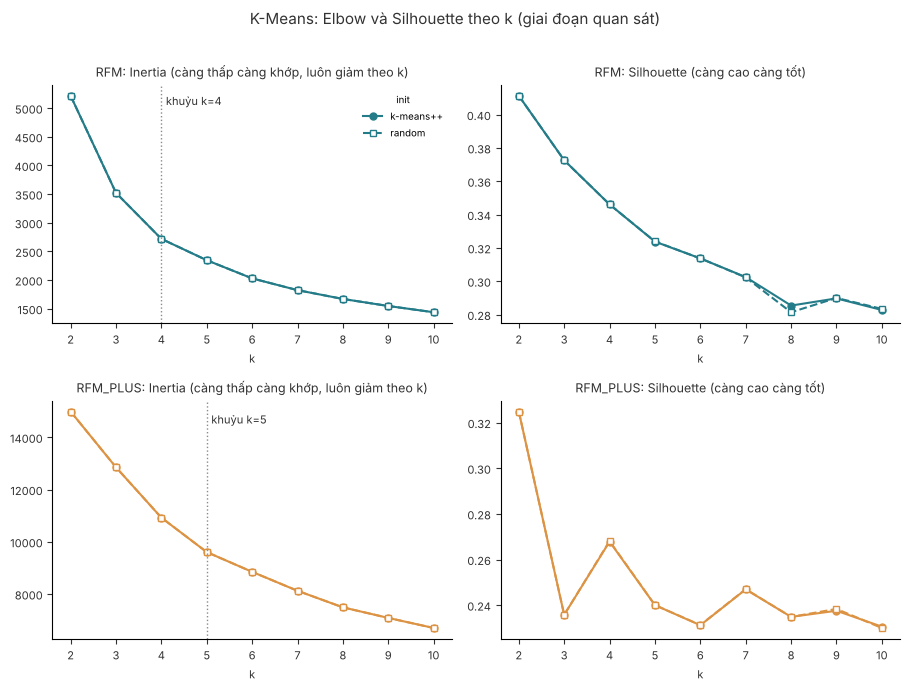

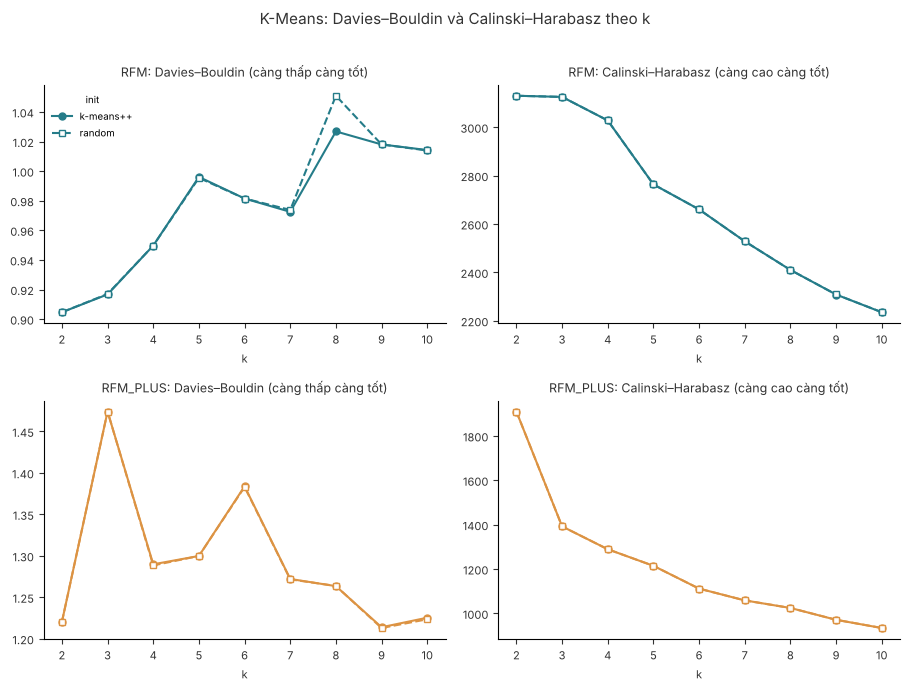

In [6]:
vk.plot_elbow_silhouette(tt, FIGURES_DIR / "kmeans_elbow_silhouette.png")
plt.show()
vk.plot_db_ch(tt, FIGURES_DIR / "kmeans_db_ch.png")
plt.show()

In [7]:
rows = []
for fs, g in best.groupby("feature_set"):
    g3 = g[g.k >= 3]
    pick = lambda d, col, fn: int(d.loc[getattr(d[col], fn)(), "k"])
    rows.append({
        "feature_set": fs, "khuỷu inertia": cl.elbow_knee(g.k, g.inertia),
        "Silhouette max": pick(g, "silhouette", "idxmax"), "DB min": pick(g, "davies_bouldin", "idxmin"),
        "CH max": pick(g, "calinski_harabasz", "idxmax"),
        "Silhouette max (k>=3)": pick(g3, "silhouette", "idxmax"), "DB min (k>=3)": pick(g3, "davies_bouldin", "idxmin"),
        "CH max (k>=3)": pick(g3, "calinski_harabasz", "idxmax"),
    })
k_pick = pd.DataFrame(rows).set_index("feature_set")
display(k_pick)

r = best.set_index(["feature_set", "k"])
pc1 = {n: PCA(random_state=SEED).fit(x).explained_variance_ratio_[0] for n, x in x_by_set.items()}
rfm_db = r.loc["RFM", "davies_bouldin"]
kd = int(k_pick.loc["RFM_PLUS", "DB min"])
max_drop5 = r.loc["RFM"].loc[5:, "inertia_drop_pct"].max()
display(Markdown(f"""**Các chỉ số xung đột nhau và không chỉ ra một k duy nhất.**

- **Calinski–Harabasz** giảm đơn điệu theo k và **Silhouette** giảm nhìn chung (`RFM_PLUS` có gợn ở k = 4 và k = 7); cả hai cao nhất ở k = 2 ở cả hai bộ đặc trưng. **Davies–Bouldin** của `RFM` gần như phẳng trong k = 2–7 ({rfm_db.loc[2:7].min():.3f}–{rfm_db.loc[2:7].max():.3f}); của `RFM_PLUS` dao động 1,2–1,5 và thấp nhất ở k = {kd} ({r.loc[('RFM_PLUS', kd), 'davies_bouldin']:.3f}), chỉ nhỉnh hơn k = 2 ({r.loc[('RFM_PLUS', 2), 'davies_bouldin']:.3f}) một chút.
- **Inertia** luôn giảm theo k. Khuỷu heuristic nằm ở k = {k_pick.loc['RFM', 'khuỷu inertia']} (`RFM`) và k = {k_pick.loc['RFM_PLUS', 'khuỷu inertia']} (`RFM_PLUS`), nhưng đường cong mượt nên khuỷu không rõ; mức giảm inertia khi thêm một cụm ở `RFM` là {r.loc[('RFM', 3), 'inertia_drop_pct']:.0f}% (lên k=3), {r.loc[('RFM', 4), 'inertia_drop_pct']:.0f}% (k=4), {r.loc[('RFM', 5), 'inertia_drop_pct']:.0f}% (k=5) và chỉ còn {r.loc[('RFM', 10), 'inertia_drop_pct']:.0f}% ở k=10.
- Silhouette của `RFM_PLUS` có đỉnh cục bộ ở k = 4 ({r.loc[('RFM_PLUS', 4), 'silhouette']:.3f}) trên nền giảm dần; đó là đỉnh cục bộ rõ nhất, còn lại các đường đi xuống khá trơn.

**Vì sao các metric thiên về k nhỏ.** Dữ liệu RFM không có các đám tách bạch mà là một **dải liên tục**: thành phần chính thứ nhất giải thích {pc1['RFM']:.0%} phương sai của `RFM` ({pc1['RFM_PLUS']:.0%} của `RFM_PLUS`), tức khách xếp dọc một trục "ít/xa → nhiều/gần". K-Means cắt dải đó thành các khúc; thêm k là cắt thêm một khúc nằm sát khúc khác, các điểm ở biên hai cụm kề nhau kéo Silhouette xuống. Silhouette tốt nhất ({r.loc[('RFM', 2), 'silhouette']:.2f} ở k=2, {r.loc[('RFM', 4), 'silhouette']:.2f} ở k=4) đều thuộc vùng cấu trúc yếu theo quy ước thường trích của Kaufman–Rousseeuw (0,26–0,50). Vì vậy phân khúc ở đây là **một cách chia hữu ích cho hành động**, không phải "cụm tự nhiên"; metric nội tại không thể tự quyết định k.

**Chọn k cho `RFM`: k = 4, với lập luận chứ không phải theo metric.**

- k = 4 là khuỷu heuristic. So với k = 3, Silhouette giảm {r.loc[('RFM', 3), 'silhouette']:.3f} → {r.loc[('RFM', 4), 'silhouette']:.3f}, DB {r.loc[('RFM', 3), 'davies_bouldin']:.3f} → {r.loc[('RFM', 4), 'davies_bouldin']:.3f}, CH {r.loc[('RFM', 3), 'calinski_harabasz']:,.0f} → {r.loc[('RFM', 4), 'calinski_harabasz']:,.0f}: k = 3 nhỉnh hơn một chút ở cả ba metric, nên đây là đánh đổi có chủ ý.
- Cái được: k = 4 tách nhóm khách "mua một lần" thành hai nhóm khác nhau về Recency (còn gần so với đã rời đi), tức nhóm có thể kéo mua lại và nhóm gần như mất (kiểm tra ở bảng hồ sơ, mục 8). Khác biệt này k = 3 gộp mất.
- Từ k ≥ 5 mỗi bước thêm cụm giảm inertia tối đa {max_drop5:.0f}% và Silhouette không còn tốt hơn k = 4 ({r.loc['RFM'].loc[5:, 'silhouette'].max():.3f} là mức cao nhất từ k = 5); ở k lớn các nghiệm cũng kém tái lập (mục 5).
- Phạm vi hợp lý cho RQ1 là **3–5 phân khúc**; k = 3 và k = 4 của `RFM` đều vào top 3 (mục 7). Kết luận cuối về RQ1 cần thêm đối chiếu giữa các thuật toán và RQ3, không thể rút ra từ K-Means một mình."""))

,khuỷu inertia,Silhouette max,DB min,CH max,Silhouette max (k>=3),DB min (k>=3),CH max (k>=3)
feature_set,,,,,,,
RFM,4,2,2,2,3,3,3
RFM_PLUS,5,2,9,2,4,9,3


**Các chỉ số xung đột nhau và không chỉ ra một k duy nhất.**

- **Calinski–Harabasz** giảm đơn điệu theo k và **Silhouette** giảm nhìn chung (`RFM_PLUS` có gợn ở k = 4 và k = 7); cả hai cao nhất ở k = 2 ở cả hai bộ đặc trưng. **Davies–Bouldin** của `RFM` gần như phẳng trong k = 2–7 (0.905–0.996); của `RFM_PLUS` dao động 1,2–1,5 và thấp nhất ở k = 9 (1.213), chỉ nhỉnh hơn k = 2 (1.220) một chút.
- **Inertia** luôn giảm theo k. Khuỷu heuristic nằm ở k = 4 (`RFM`) và k = 5 (`RFM_PLUS`), nhưng đường cong mượt nên khuỷu không rõ; mức giảm inertia khi thêm một cụm ở `RFM` là 32% (lên k=3), 23% (k=4), 14% (k=5) và chỉ còn 7% ở k=10.
- Silhouette của `RFM_PLUS` có đỉnh cục bộ ở k = 4 (0.268) trên nền giảm dần; đó là đỉnh cục bộ rõ nhất, còn lại các đường đi xuống khá trơn.

**Vì sao các metric thiên về k nhỏ.** Dữ liệu RFM không có các đám tách bạch mà là một **dải liên tục**: thành phần chính thứ nhất giải thích 73% phương sai của `RFM` (52% của `RFM_PLUS`), tức khách xếp dọc một trục "ít/xa → nhiều/gần". K-Means cắt dải đó thành các khúc; thêm k là cắt thêm một khúc nằm sát khúc khác, các điểm ở biên hai cụm kề nhau kéo Silhouette xuống. Silhouette tốt nhất (0.41 ở k=2, 0.35 ở k=4) đều thuộc vùng cấu trúc yếu theo quy ước thường trích của Kaufman–Rousseeuw (0,26–0,50). Vì vậy phân khúc ở đây là **một cách chia hữu ích cho hành động**, không phải "cụm tự nhiên"; metric nội tại không thể tự quyết định k.

**Chọn k cho `RFM`: k = 4, với lập luận chứ không phải theo metric.**

- k = 4 là khuỷu heuristic. So với k = 3, Silhouette giảm 0.373 → 0.346, DB 0.917 → 0.950, CH 3,125 → 3,028: k = 3 nhỉnh hơn một chút ở cả ba metric, nên đây là đánh đổi có chủ ý.
- Cái được: k = 4 tách nhóm khách "mua một lần" thành hai nhóm khác nhau về Recency (còn gần so với đã rời đi), tức nhóm có thể kéo mua lại và nhóm gần như mất (kiểm tra ở bảng hồ sơ, mục 8). Khác biệt này k = 3 gộp mất.
- Từ k ≥ 5 mỗi bước thêm cụm giảm inertia tối đa 14% và Silhouette không còn tốt hơn k = 4 (0.324 là mức cao nhất từ k = 5); ở k lớn các nghiệm cũng kém tái lập (mục 5).
- Phạm vi hợp lý cho RQ1 là **3–5 phân khúc**; k = 3 và k = 4 của `RFM` đều vào top 3 (mục 7). Kết luận cuối về RQ1 cần thêm đối chiếu giữa các thuật toán và RQ3, không thể rút ra từ K-Means một mình.

## 5. `init` có ảnh hưởng không?

Hai đường `init` gần trùng nhau ở mục 4. Kiểm tra kỹ hơn: với mỗi k, hai cách khởi tạo cho chênh lệch inertia tương đối bao nhiêu và có ra **cùng phân hoạch** không (ARI giữa hai nhãn).

In [8]:
agree = pd.concat({n: cl.kmeans_init_agreement(x) for n, x in x_by_set.items()}, names=["feature_set"])
with pd.option_context("display.float_format", "{:.5f}".format):
    display(agree.unstack("feature_set"))

big = agree[agree.index.get_level_values("k") >= 8]
display(Markdown(f"""**Đọc kết quả.**

- Chênh lệch inertia giữa hai `init` rất nhỏ ở mọi k (tối đa {agree.rel_inertia_diff.abs().max():.4%}). Với k ≤ 7, ARI ≥ {agree[agree.index.get_level_values("k") <= 7].ari.min():.3f}: hai cách khởi tạo cho thực chất cùng một phân hoạch.
- Ở k ≥ 8, ARI giữa hai `init` thấp nhất là {big.loc['RFM'].ari.min():.3f} với `RFM` (k = {int(big.loc['RFM'].ari.idxmin())}) và {big.loc['RFM_PLUS'].ari.min():.3f} với `RFM_PLUS` (k = {int(big.loc['RFM_PLUS'].ari.idxmin())}) dù inertia gần như bằng nhau: có **nhiều nghiệm gần tương đương nhưng khác nhau**, nên phân hoạch ở k lớn phụ thuộc khởi tạo nhiều hơn ở k nhỏ. Đây là lý do thêm để không chọn k lớn.
- Hệ quả cho cách chọn: bước "mỗi (bộ đặc trưng, k) lấy `init` có inertia thấp nhất" chỉ là phá hòa giữa hai nghiệm gần như giống hệt ở k nhỏ; đừng đọc việc `random` hay `k-means++` được chọn như một kết luận về chất lượng. Kết quả của mô hình không phụ thuộc `init` trong vùng k đang xét (3–5)."""))

rel_inertia_diff              ari         
feature_set              RFM RFM_PLUS     RFM RFM_PLUS
k                                                     
2                    0.00000  0.00000 1.00000  1.00000
3                    0.00000  0.00000 0.99816  1.00000
4                    0.00000 -0.00001 1.00000  0.99488
5                    0.00003  0.00000 0.99832  1.00000
6                    0.00000  0.00000 1.00000  0.98420
7                    0.00002 -0.00000 0.98937  0.99743
8                   -0.00001  0.00000 0.85828  0.99601
9                   -0.00005 -0.00010 0.99491  0.97386
10                  -0.00010 -0.00011 0.96366  0.97891

**Đọc kết quả.**

- Chênh lệch inertia giữa hai `init` rất nhỏ ở mọi k (tối đa 0.0114%). Với k ≤ 7, ARI ≥ 0.984: hai cách khởi tạo cho thực chất cùng một phân hoạch.
- Ở k ≥ 8, ARI giữa hai `init` thấp nhất là 0.858 với `RFM` (k = 8) và 0.974 với `RFM_PLUS` (k = 9) dù inertia gần như bằng nhau: có **nhiều nghiệm gần tương đương nhưng khác nhau**, nên phân hoạch ở k lớn phụ thuộc khởi tạo nhiều hơn ở k nhỏ. Đây là lý do thêm để không chọn k lớn.
- Hệ quả cho cách chọn: bước "mỗi (bộ đặc trưng, k) lấy `init` có inertia thấp nhất" chỉ là phá hòa giữa hai nghiệm gần như giống hệt ở k nhỏ; đừng đọc việc `random` hay `k-means++` được chọn như một kết luận về chất lượng. Kết quả của mô hình không phụ thuộc `init` trong vùng k đang xét (3–5).

## 6. `RFM` so với `RFM_PLUS`: đặc trưng mở rộng có cải thiện cấu trúc cụm không?

Không kết luận mặc định "nhiều đặc trưng thì tốt hơn". Ba loại bằng chứng, đều chỉ dùng chỉ số nội tại:

1. **Metric trong không gian riêng** của mỗi bộ ở cùng k (k = 4, cả hai đều vào danh sách ứng viên). Silhouette và DB tương đối so được; CH và inertia thì không (khác số chiều).
2. **Đo chéo**: nhãn của bộ này đo trong không gian của bộ kia. Mỗi nhãn tất nhiên tốt nhất trong không gian đã sinh ra nó, nên đo chéo không chọn người thắng; nó cho biết hai phân hoạch có giống nhau không.
3. **Độ nhạy khi bỏ bớt cột của `RFM_PLUS`** (cùng k, cùng cấu hình): cột nào làm đổi phân hoạch (ARI thấp so với bản đủ 7 cột) và cột nào làm Silhouette tốt lên hay xấu đi. Có thêm kịch bản **bỏ `Monetary`** vì tuần 2 báo `Monetary`, `Frequency`, `AvgOrderValue` gần đồng tuyến (VIF ở bảng dưới).

In [9]:
display(pd.read_csv(TABLES_DIR / "feature_redundancy.csv", index_col=0).round(2).T)

K_CMP = 4
lab_cmp = {n: cl.order_labels_by_size(cl.run_kmeans(x, K_CMP)[1]) for n, x in x_by_set.items()}

own = pd.DataFrame({n: cl.internal_metrics(x_by_set[n], lab_cmp[n]) for n in x_by_set}).T
display(Markdown("**(1) Metric trong không gian riêng (k = 4)**"))
display(own)

display(Markdown("**(2) Đo chéo**"))
cross = cl.cross_evaluation(lab_cmp, x_by_set)
display(cross)
ari_sets = adjusted_rand_score(lab_cmp["RFM"], lab_cmp["RFM_PLUS"])
print(f"ARI giữa phân hoạch RFM và RFM_PLUS (k=4): {ari_sets:.3f}")

drops = {
    "bỏ Monetary": ["Monetary"],
    "bỏ AvgInterPurchaseDays": ["AvgInterPurchaseDays"],
    "bỏ CancelRate": ["CancelRate"],
    "bỏ AvgOrderValue + NUniqueProducts": ["AvgOrderValue", "NUniqueProducts"],
    "chỉ RFM (bỏ 4 cột thêm)": RFM_PLUS[3:],
}
sens, sens_labels = cl.kmeans_drop_feature_sensitivity(x_by_set["RFM_PLUS"], K_CMP, drops)
display(Markdown("**(3) Độ nhạy khi bỏ cột của `RFM_PLUS` (k = 4; metric đo trong không gian của chính kịch bản)**"))
display(sens)

,Recency,Frequency,Monetary,AvgOrderValue,NUniqueProducts,AvgInterPurchaseDays,CancelRate
VIF,1.530,276.210,766.630,297.020,1.970,10.400,1.060
max_abs_r,0.520,0.790,0.780,0.730,0.690,0.790,0.230


**(1) Metric trong không gian riêng (k = 4)**

,silhouette,davies_bouldin,calinski_harabasz
RFM,0.346,0.950,"3,028.146"
RFM_PLUS,0.268,1.290,"1,289.351"


**(2) Đo chéo**

,labels_from,measured_in,silhouette,davies_bouldin,calinski_harabasz
0,RFM,RFM,0.346,0.950,"3,028.146"
1,RFM,RFM_PLUS,0.165,1.826,992.290
2,RFM_PLUS,RFM,0.127,2.268,"1,366.699"
3,RFM_PLUS,RFM_PLUS,0.268,1.290,"1,289.351"


ARI giữa phân hoạch RFM và RFM_PLUS (k=4): 0.316


**(3) Độ nhạy khi bỏ cột của `RFM_PLUS` (k = 4; metric đo trong không gian của chính kịch bản)**

,n_features,ari_vs_full,silhouette,davies_bouldin,calinski_harabasz
scenario,,,,,
RFM_PLUS (đủ 7 cột),7,1.000,0.268,1.290,"1,289.351"
bỏ Monetary,6,0.880,0.264,1.330,"1,226.448"
bỏ AvgInterPurchaseDays,6,0.544,0.251,1.274,"1,284.515"
bỏ CancelRate,6,0.567,0.265,1.270,"1,668.288"
bỏ AvgOrderValue + NUniqueProducts,5,0.827,0.361,1.035,"2,067.765"
chỉ RFM (bỏ 4 cột thêm),3,0.316,0.346,0.950,"3,028.146"


In [10]:
c = cross.set_index(["labels_from", "measured_in"])
s3 = sens["silhouette"]
display(Markdown(f"""**Kết luận từ bằng chứng.**

- **Không có bằng chứng nội tại rằng `RFM_PLUS` cải thiện cấu trúc cụm.** Trong không gian riêng, `RFM_PLUS` tách kém hơn: Silhouette {own.loc['RFM_PLUS', 'silhouette']:.3f} so với {own.loc['RFM', 'silhouette']:.3f}, Davies–Bouldin {own.loc['RFM_PLUS', 'davies_bouldin']:.3f} so với {own.loc['RFM', 'davies_bouldin']:.3f}. (CH và inertia không dùng để so ở bước này.)
- **Nhưng `RFM_PLUS` cho một phân hoạch khác chứ không phải bản tinh chỉnh của `RFM`:** ARI giữa hai nhãn chỉ {ari_sets:.2f}. Nhãn `RFM` đo trong không gian `RFM_PLUS` có Silhouette {c.loc[('RFM', 'RFM_PLUS'), 'silhouette']:.3f}, nhãn `RFM_PLUS` đo trong không gian `RFM` chỉ {c.loc[('RFM_PLUS', 'RFM'), 'silhouette']:.3f}: các cụm của `RFM_PLUS` chồng lấn mạnh nếu chỉ nhìn qua R, F, M.
- **Cột nào đóng góp gì:** bỏ `AvgInterPurchaseDays` hoặc `CancelRate` làm phân hoạch đổi rõ (ARI so với bản đủ lần lượt {sens.loc['bỏ AvgInterPurchaseDays', 'ari_vs_full']:.2f} và {sens.loc['bỏ CancelRate', 'ari_vs_full']:.2f}), nghĩa là hai cột này mang cấu trúc mà R, F, M không có (xem cụm có `CancelRate` cao ở mục 8). Ngược lại bỏ `AvgOrderValue` + `NUniqueProducts` giữ phân hoạch khá giống (ARI {sens.loc['bỏ AvgOrderValue + NUniqueProducts', 'ari_vs_full']:.2f}) và **làm Silhouette tốt lên** ({s3['RFM_PLUS (đủ 7 cột)']:.3f} → {s3['bỏ AvgOrderValue + NUniqueProducts']:.3f}): hai cột này thêm chiều nhưng không thêm khả năng tách, phù hợp với việc chúng tương quan khá mạnh với `Monetary` (|r| 0,69–0,73). Đây là gợi ý chứ chưa phải bằng chứng nhân quả, và Silhouette giữa các kịch bản khác số chiều chỉ tương đối so được. Bỏ `Monetary` cho Silhouette {s3['bỏ Monetary']:.3f} và ARI {sens.loc['bỏ Monetary', 'ari_vs_full']:.2f}, tức `Monetary` bị `AvgOrderValue` và `Frequency` thay thế một phần nên không phải cột không thể thiếu.
- **Điều metric nội tại không trả lời được:** cụm "hay hủy đơn" có đáng thành một phân khúc hay không, tức có dự báo hành vi tương lai khác không, là việc của RQ3 sau khi nhóm chốt mô hình. Ở đây chỉ khẳng định: mở rộng đặc trưng **làm đổi phân hoạch và giảm độ tách trong không gian của nó**, chưa chứng minh được là cải thiện."""))

**Kết luận từ bằng chứng.**

- **Không có bằng chứng nội tại rằng `RFM_PLUS` cải thiện cấu trúc cụm.** Trong không gian riêng, `RFM_PLUS` tách kém hơn: Silhouette 0.268 so với 0.346, Davies–Bouldin 1.290 so với 0.950. (CH và inertia không dùng để so ở bước này.)
- **Nhưng `RFM_PLUS` cho một phân hoạch khác chứ không phải bản tinh chỉnh của `RFM`:** ARI giữa hai nhãn chỉ 0.32. Nhãn `RFM` đo trong không gian `RFM_PLUS` có Silhouette 0.165, nhãn `RFM_PLUS` đo trong không gian `RFM` chỉ 0.127: các cụm của `RFM_PLUS` chồng lấn mạnh nếu chỉ nhìn qua R, F, M.
- **Cột nào đóng góp gì:** bỏ `AvgInterPurchaseDays` hoặc `CancelRate` làm phân hoạch đổi rõ (ARI so với bản đủ lần lượt 0.54 và 0.57), nghĩa là hai cột này mang cấu trúc mà R, F, M không có (xem cụm có `CancelRate` cao ở mục 8). Ngược lại bỏ `AvgOrderValue` + `NUniqueProducts` giữ phân hoạch khá giống (ARI 0.83) và **làm Silhouette tốt lên** (0.268 → 0.361): hai cột này thêm chiều nhưng không thêm khả năng tách, phù hợp với việc chúng tương quan khá mạnh với `Monetary` (|r| 0,69–0,73). Đây là gợi ý chứ chưa phải bằng chứng nhân quả, và Silhouette giữa các kịch bản khác số chiều chỉ tương đối so được. Bỏ `Monetary` cho Silhouette 0.264 và ARI 0.88, tức `Monetary` bị `AvgOrderValue` và `Frequency` thay thế một phần nên không phải cột không thể thiếu.
- **Điều metric nội tại không trả lời được:** cụm "hay hủy đơn" có đáng thành một phân khúc hay không, tức có dự báo hành vi tương lai khác không, là việc của RQ3 sau khi nhóm chốt mô hình. Ở đây chỉ khẳng định: mở rộng đặc trưng **làm đổi phân hoạch và giảm độ tách trong không gian của nó**, chưa chứng minh được là cải thiện.

## 7. Top 3 cấu hình theo chỉ số nội tại và lưu nhãn

Quy tắc chọn đã đặt trong `kmeans_select_top`, cố định và không chỉnh theo kết quả:

1. Chỉ xét k ≥ 3. **Đây là phán đoán theo ý nghĩa kinh doanh, không phải theo metric**: k = 2 có Silhouette và CH cao nhất ở cả hai bộ nhưng chỉ tách "còn hoạt động" khỏi "đã im lặng", không đủ làm phân khúc cho RQ1. k = 2 vẫn nằm trong bảng tuning đầy đủ.
2. Xếp hạng **trong từng bộ đặc trưng** cho mỗi metric (metric không so được giữa 3 và 7 chiều), lấy hạng trung bình của Silhouette, DB, CH rồi quy về [0, 1].
3. Lấy 3 cấu hình có hạng thấp nhất; hòa thì ưu tiên Silhouette tốt hơn rồi k nhỏ hơn.

Hệ quả cần biết: hạng chuẩn hóa trong từng bộ khiến cấu hình tốt nhất của mỗi bộ luôn có điểm tốt; nó không nói bộ nào tốt hơn tuyệt đối (việc đó ở mục 6).

In [11]:
top = cl.kmeans_select_top(best)
top.to_csv(TABLES_DIR / "kmeans_top3_selection.csv", index=False, encoding="utf-8-sig")
cols = ["feature_set", "k", "init", "silhouette", "davies_bouldin", "calinski_harabasz",
        "rank_silhouette", "rank_davies_bouldin", "rank_calinski_harabasz", "rank_pct", "selected"]
display(top[cols].head(8))

selected = top[top.selected].reset_index(drop=True)
assert len(selected) == 3
labels_sel = {}   # (feature_set, k) -> nhãn đã đánh lại theo kích thước giảm dần
for row in selected.itertuples():
    model, lab = cl.run_kmeans(x_by_set[row.feature_set], int(row.k), row.init)
    # nhãn lưu ra phải khớp đúng dòng tuning đã ghi (tái lập)
    t = tuning[(tuning.feature_set == row.feature_set) & (tuning.params == json.dumps(
        {"k": int(row.k), "init": row.init, "n_init": KMEANS_N_INIT, "random_state": SEED}))].iloc[0]
    assert np.isclose(cl.internal_metrics(x_by_set[row.feature_set], lab)["silhouette"], t.silhouette)
    assert np.isclose(model.inertia_, t.inertia)
    labels_sel[(row.feature_set, int(row.k))] = cl.order_labels_by_size(lab)
    path = cl.save_kmeans_labels(feats.index, lab, row.feature_set, int(row.k))
    saved = pd.read_csv(path, index_col="CustomerID")
    assert saved.index.equals(feats.index) and saved.Cluster.nunique() == int(row.k)
    print("Đã lưu", path.relative_to(ROOT), f"({int(row.k)} cụm, {len(saved):,} khách)")

# Phân hoạch có phụ thuộc init được chọn không? (ARI giữa init chọn và init còn lại ở cùng k)
for fs, k in labels_sel:
    other = [i for i in KMEANS_INITS if i != selected[(selected.feature_set == fs) & (selected.k == k)].init.iloc[0]][0]
    ari_i = adjusted_rand_score(labels_sel[(fs, k)], cl.run_kmeans(x_by_set[fs], k, other)[1])
    print(f"{fs} k={k}: ARI giữa hai init = {ari_i:.4f}")

,feature_set,k,init,silhouette,davies_bouldin,calinski_harabasz,rank_silhouette,rank_davies_bouldin,rank_calinski_harabasz,rank_pct,selected
0,RFM,3,k-means++,0.373,0.917,"3,125.454",1.000,1.000,1.000,0.000,True
1,RFM,4,k-means++,0.346,0.950,"3,028.146",2.000,2.000,2.000,0.143,True
2,RFM_PLUS,4,random,0.268,1.288,"1,289.370",1.000,5.000,2.000,0.238,True
3,RFM_PLUS,7,random,0.247,1.272,"1,058.804",2.000,4.000,5.000,0.381,False
4,RFM,5,k-means++,0.324,0.996,"2,763.919",3.000,5.000,3.000,0.381,False
5,RFM_PLUS,5,k-means++,0.240,1.300,"1,214.625",3.000,6.000,3.000,0.429,False
6,RFM,6,k-means++,0.314,0.982,"2,660.488",4.000,4.000,4.000,0.429,False
7,RFM_PLUS,9,random,0.238,1.213,971.412,4.000,1.000,7.000,0.429,False


Đã lưu reports/tables/labels_kmeans_RFM_k3.csv (3 cụm, 3,360 khách)
Đã lưu reports/tables/labels_kmeans_RFM_k4.csv (4 cụm, 3,360 khách)
Đã lưu reports/tables/labels_kmeans_RFM_PLUS_k4.csv (4 cụm, 3,360 khách)
RFM k=3: ARI giữa hai init = 0.9982
RFM k=4: ARI giữa hai init = 1.0000
RFM_PLUS k=4: ARI giữa hai init = 0.9949


## 8. Phân tích sơ bộ: kích thước cụm, cụm quá nhỏ, ngoại lệ và tâm cụm

### 8.1 Có cụm quá nhỏ không, từ k nào?

Cờ "cụm nhỏ": dưới 2% tổng số khách hoặc dưới 30 khách (dưới 30 thì trung bình/trung vị của hồ sơ cụm quá nhiễu để diễn giải; dưới 2% thì khó thành một phân khúc để marketing hành động). Quét mọi cấu hình tốt nhất theo từng (bộ đặc trưng, k).

In [12]:
scan = cl.kmeans_size_scan(x_by_set, best)
display(pd.concat({c: scan.pivot(index="k", columns="feature_set", values=c) for c in ["min_n", "min_frac", "n_small"]}, axis=1))
display(Markdown(f"""Số cụm bị cờ "nhỏ" trên toàn lưới: **{int(scan.n_small.sum())}**. Cụm nhỏ nhất trên toàn lưới có {int(scan.min_n.min())} khách ({scan.min_frac.min():.1%}), ở k = {int(scan.loc[scan.min_n.idxmin(), 'k'])} của `{scan.loc[scan.min_n.idxmin(), 'feature_set']}`.

Điều này **không** có nghĩa dữ liệu không có ngoại lệ: Monetary lệch phải rất mạnh (skew gốc trên 16). Trên dữ liệu đã log1p, những khách khổng lồ không tự thành cụm riêng mà nằm trong cụm giá trị cao và **kéo tâm cụm đó** (xem 8.3). Chưa chạy bản không log1p nên chưa nói được log1p là nguyên nhân duy nhất."""))

min_n          min_frac          n_small         
feature_set   RFM RFM_PLUS      RFM RFM_PLUS     RFM RFM_PLUS
k                                                            
2            1389     1662    0.413    0.495       0        0
3             856      840    0.255    0.250       0        0
4             476      398    0.142    0.118       0        0
5             188      406    0.056    0.121       0        0
6             188      311    0.056    0.093       0        0
7             183      224    0.054    0.067       0        0
8             138      213    0.041    0.063       0        0
9             138      162    0.041    0.048       0        0
10            134      171    0.040    0.051       0        0

Số cụm bị cờ "nhỏ" trên toàn lưới: **0**. Cụm nhỏ nhất trên toàn lưới có 134 khách (4.0%), ở k = 10 của `RFM`.

Điều này **không** có nghĩa dữ liệu không có ngoại lệ: Monetary lệch phải rất mạnh (skew gốc trên 16). Trên dữ liệu đã log1p, những khách khổng lồ không tự thành cụm riêng mà nằm trong cụm giá trị cao và **kéo tâm cụm đó** (xem 8.3). Chưa chạy bản không log1p nên chưa nói được log1p là nguyên nhân duy nhất.

### 8.2 Hồ sơ cụm của ba cấu hình được chọn

Hồ sơ theo **đơn vị gốc**, đặt trung bình cạnh trung vị: K-Means dùng trung bình nên tâm cụm bị kéo về đuôi phải; trung vị mô tả khách điển hình. Cột `SinglePurchase_share` là tỷ lệ khách chỉ có một hóa đơn trong cụm; với họ `AvgInterPurchaseDays` là **giá trị điền** (độ dài giai đoạn quan sát), không phải khoảng cách đo được, nên đọc cột này của `RFM_PLUS` cùng với tỷ lệ đó.

In [13]:
profiles = {}
for (fs, k), lab in labels_sel.items():
    prof = cl.kmeans_profile(feats, lab, FEATURE_SETS[fs])
    prof[("SinglePurchase_share", "")] = feats.groupby(lab).SinglePurchase.mean().to_numpy()
    prof[("share_of_customers", "")] = prof[("n", "customers")] / len(feats)
    profiles[f"{fs}_k{k}"] = prof
    display(Markdown(f"**{fs}, k = {k}**"))
    display(prof)
pd.concat(profiles, names=["config", "cluster"]).to_csv(TABLES_DIR / "kmeans_top3_profile.csv", encoding="utf-8-sig")

**RFM, k = 3**

n    mean                      median                     SinglePurchase_share share_of_customers
        customers Recency Frequency  Monetary Recency Frequency  Monetary                                        
cluster                                                                                                          
0            1524  62.064     1.997   621.411  59.000     2.000   500.430                0.369              0.454
1             980 199.583     1.239   344.896 193.000     1.000   246.275                0.823              0.292
2             856  34.121     8.776 4,730.841  22.000     6.000 2,284.955                0.001              0.255

**RFM, k = 4**

n    mean                      median                     SinglePurchase_share share_of_customers
        customers Recency Frequency  Monetary Recency Frequency  Monetary                                        
cluster                                                                                                          
0            1115  56.541     3.290 1,301.456  47.000     3.000 1,002.910                0.034              0.332
1             889 207.322     1.247   354.985 199.000     1.000   265.850                0.811              0.265
2             880  68.634     1.348   300.690  72.000     1.000   286.215                0.694              0.262
3             476  24.443    12.200 6,939.738  16.000     9.000 3,271.880                0.000              0.142

**RFM_PLUS, k = 4**

n    mean                                                                                    median                                                                                   SinglePurchase_share share_of_customers
        customers Recency Frequency  Monetary AvgOrderValue NUniqueProducts AvgInterPurchaseDays CancelRate Recency Frequency  Monetary AvgOrderValue NUniqueProducts AvgInterPurchaseDays CancelRate                                        
cluster                                                                                                                                                                                                                                      
0            1197 142.388     1.043   294.308       288.823          18.454              275.805      0.000 145.000     1.000   219.520       210.000          14.000              282.000      0.000                0.957              0.356
1            1023  70.846     3.031   775.690       284.421          42.945               69.051      0.041  56.000     3.000   686.630       232.340          35.000               55.031      0.000                0.017              0.304
2             742  33.853     9.139 5,195.292       596.426         120.515               40.443      0.172  22.000     7.000 2,516.155       400.752          94.000               33.995      0.167                0.003              0.221
3             398 129.028     1.608   838.953       632.653          29.304              185.475      0.463 115.000     1.000   460.335       316.123          21.000              282.000      0.500                0.515              0.118

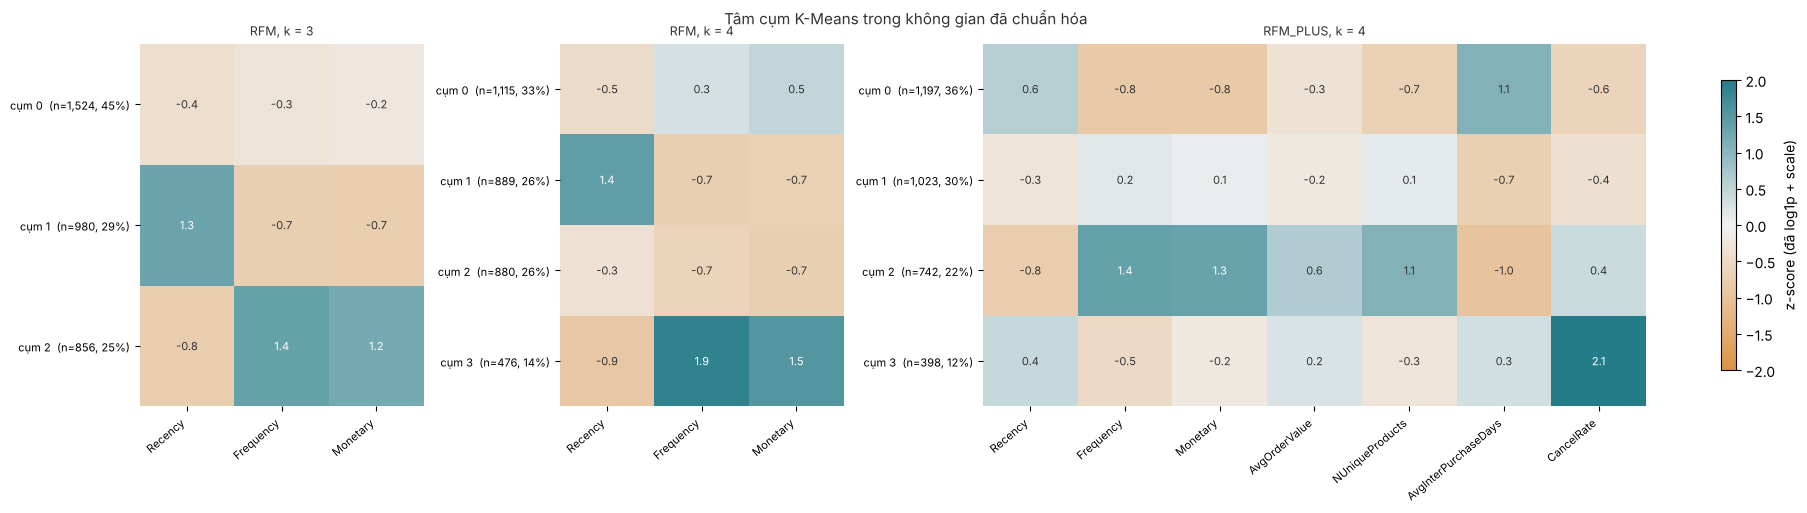

In [14]:
items = []
for (fs, k), lab in labels_sel.items():
    items.append((f"{fs}, k = {k}", cl.kmeans_centroids(x_by_set[fs], lab), pd.Series(lab).value_counts().sort_index()))
vk.plot_centroid_heatmaps(items, FIGURES_DIR / "kmeans_centroids_top3.png")
plt.show()

In [15]:
prof_p = profiles["RFM_PLUS_k4"]
lab_p = labels_sel[("RFM_PLUS", 4)]
c_cancel = prof_p[("mean", "CancelRate")].idxmax()
c_big = prof_p[("n", "customers")].idxmax()
in_c, in_b = feats.loc[lab_p == c_cancel], feats.loc[lab_p == c_big]
display(Markdown(f"""**Hai điều cần đọc kỹ ở `RFM_PLUS`, k = 4** (số liệu tính từ bảng ở trên):

- **Cụm lớn nhất (cụm {c_big}, {len(in_b):,} khách) chịu ảnh hưởng của giá trị điền:** {in_b.SinglePurchase.mean():.0%} khách trong cụm chỉ mua một lần nên `AvgInterPurchaseDays` của họ là giá trị điền (trung vị {in_b.AvgInterPurchaseDays.median():.0f} ngày = độ dài giai đoạn quan sát), không phải nhịp mua đo được. Một phần sự tách của cụm này khỏi các cụm khác đến từ giá trị điền đó; chưa tách riêng được mức đóng góp.
- **Cụm `CancelRate` cao (cụm {c_cancel}, {len(in_c):,} khách) dựa trên mẫu rất nhỏ:** {(in_c.Frequency <= 2).mean():.0%} khách trong cụm có tối đa 2 hóa đơn bán, nên chỉ một hóa đơn hủy đã cho `CancelRate` rất cao (1 bán + 1 hủy = 0,5). Nhóm này phản ánh "đã từng hủy" nhiều hơn "hủy thường xuyên"."""))

**Hai điều cần đọc kỹ ở `RFM_PLUS`, k = 4** (số liệu tính từ bảng ở trên):

- **Cụm lớn nhất (cụm 0, 1,197 khách) chịu ảnh hưởng của giá trị điền:** 96% khách trong cụm chỉ mua một lần nên `AvgInterPurchaseDays` của họ là giá trị điền (trung vị 282 ngày = độ dài giai đoạn quan sát), không phải nhịp mua đo được. Một phần sự tách của cụm này khỏi các cụm khác đến từ giá trị điền đó; chưa tách riêng được mức đóng góp.
- **Cụm `CancelRate` cao (cụm 3, 398 khách) dựa trên mẫu rất nhỏ:** 91% khách trong cụm có tối đa 2 hóa đơn bán, nên chỉ một hóa đơn hủy đã cho `CancelRate` rất cao (1 bán + 1 hủy = 0,5). Nhóm này phản ánh "đã từng hủy" nhiều hơn "hủy thường xuyên".

**Đọc hồ sơ (mô tả theo đặc điểm, không theo số thứ tự cụm vì thứ tự chỉ là kích thước giảm dần).**

- **`RFM`, k = 3:** ba mức dọc một trục: khách giá trị cao mua dày và vừa mua gần đây; nhóm giữa mua khoảng hai hóa đơn, lần cuối cách đây khoảng hai tháng; nhóm đã lâu không mua, đa số chỉ một hóa đơn và chi tiêu thấp. Dễ đọc, nhưng khách mua một lần còn gần bị gộp vào nhóm giữa.
- **`RFM`, k = 4:** tách thêm một nhóm trong những khách mua ít, chi tiêu thấp: nhóm **chủ yếu mua một lần và còn gần** (Recency trung vị khoảng 70 ngày) so với nhóm **chủ yếu mua một lần và đã rời đi** (Recency trung vị khoảng 200 ngày). Frequency và Monetary của hai nhóm gần nhau, chỉ khác Recency, nên đây là khác biệt "còn có thể kéo mua lại" so với "gần như mất", đúng lý do chọn k = 4 ở mục 4. Hai nhóm còn lại là nhóm mua đều (trung vị 3 hóa đơn) và nhóm giá trị cao.
- **`RFM_PLUS`, k = 4:** không còn nhóm "mua một lần và còn gần". Thay vào đó có cụm `CancelRate` cao (thông tin R, F, M không thấy), nhưng hai điều ở ô trên cho thấy cụm hay hủy dựa trên mẫu nhỏ và cụm lớn nhất chịu ảnh hưởng của giá trị điền. Hai cụm còn lại là nhóm mua đều và nhóm giá trị cao. Đây là minh họa cho kết luận mục 6: mở rộng đặc trưng đổi cách chia, nhưng không rõ ràng tốt hơn.
- Ở cả ba cấu hình, **trung bình lớn hơn trung vị rõ rệt ở Monetary và Frequency của cụm giá trị cao**: tâm cụm bị kéo bởi đuôi phải ngay cả sau log1p (8.3 đo mức kéo).

### 8.3 Ngoại lệ ảnh hưởng thế nào lên tâm cụm?

Thí nghiệm: bỏ 1% khách **xa tâm cụm của chính họ nhất** trong mô hình đầy đủ, huấn luyện lại cùng cấu hình (cùng k, init, `n_init`, seed, **không fit lại scaler**), ghép tâm cụm hai mô hình bằng thuật toán Hungarian (nhãn số có thể hoán vị) rồi đo (a) độ dịch tâm cụm, tính bằng độ lệch chuẩn trong không gian đã scale; (b) ARI trên các khách còn lại; (c) phần inertia mà 1% điểm bị loại đóng góp. Đây là kiểm tra độ nhạy, không dùng để chọn mô hình.

In [16]:
outlier = {}
for (fs, k), lab in labels_sel.items():
    init = selected[(selected.feature_set == fs) & (selected.k == k)].init.iloc[0]
    shift, summ, _ = cl.kmeans_outlier_sensitivity(x_by_set[fs], k, init)
    outlier[(fs, k)] = (shift, summ)
    display(Markdown(f"**{fs}, k = {k}** — bỏ {summ['n_removed']} khách; ARI trên điểm còn lại = {summ['ari_retained']:.3f}; "
                     f"dịch tâm lớn nhất = {summ['max_centroid_shift']:.3f} sd; "
                     f"phần inertia của {summ['n_removed']} khách này = {summ['inertia_share_removed']:.1%}"))
    display(shift)

**RFM, k = 3** — bỏ 34 khách; ARI trên điểm còn lại = 0.919; dịch tâm lớn nhất = 0.188 sd; phần inertia của 34 khách này = 12.2%

,n_full,n_removed,centroid_shift
cluster,,,
0,1524,3,0.060
1,980,4,0.031
2,856,27,0.188


**RFM, k = 4** — bỏ 34 khách; ARI trên điểm còn lại = 0.929; dịch tâm lớn nhất = 0.283 sd; phần inertia của 34 khách này = 12.0%

,n_full,n_removed,centroid_shift
cluster,,,
0,1115,1,0.081
1,889,4,0.006
2,880,4,0.006
3,476,25,0.283


**RFM_PLUS, k = 4** — bỏ 34 khách; ARI trên điểm còn lại = 0.933; dịch tâm lớn nhất = 0.162 sd; phần inertia của 34 khách này = 8.2%

,n_full,n_removed,centroid_shift
cluster,,,
0,1197,13,0.078
1,1023,1,0.101
2,742,15,0.162
3,398,5,0.087


In [17]:
lines = []
for (fs, k), (shift, summ) in outlier.items():
    w = shift.centroid_shift.idxmax()
    lines.append(f"- `{fs}`, k = {k}: {summ['n_removed']} khách ({summ['n_removed'] / len(feats):.1%}) chiếm {summ['inertia_share_removed']:.1%} inertia; "
                 f"tâm dịch nhiều nhất ở cụm {w} ({shift.loc[w, 'centroid_shift']:.2f} sd) với {int(shift.loc[w, 'n_removed'])}/{summ['n_removed']} khách bị loại; "
                 f"ARI sau cắt {summ['ari_retained']:.2f}.")
display(Markdown("**Đọc kết quả.**\n\n" + "\n".join(lines) + """

- **Cụm có nhiều khách bị loại nhất cũng là cụm có tâm dịch nhiều nhất** ở cả ba cấu hình. Ở `RFM` ngoại lệ tập trung rõ vào cụm giá trị cao (trên 70% số khách bị loại); ở `RFM_PLUS` phân tán hơn giữa các cụm và tâm dịch nhỏ hơn. Ảnh hưởng nhìn chung **cục bộ**, không làm hỏng cả mô hình.
- **Cấu trúc tổng thể vẫn giữ:** ARI sau khi loại 1% điểm xa nhất vẫn trên 0,9 ở cả ba cấu hình, nên các phân khúc không phụ thuộc vào vài khách đơn lẻ. Mức dịch tâm tối đa dưới 0,3 độ lệch chuẩn, nhỏ so với chênh lệch giữa các tâm cụm trên các trục chính (cỡ 2–3 sd, xem heatmap).
- **Nhưng 1% điểm đóng góp khoảng 8–12% inertia**: hàm mục tiêu của K-Means bị chi phối bởi đuôi, vì lỗi được bình phương. Sau log1p ảnh hưởng đã giảm nhiều (Monetary từ skew 16 xuống 0,4) nhưng chưa mất. Đây là điểm yếu cố hữu của K-Means (tâm = trung bình, mục tiêu bình phương) nên đáng đối chiếu với các thuật toán khác ở phần so sánh.
- Hạn chế: thí nghiệm chỉ bỏ điểm xa tâm theo mô hình đầy đủ, không xét ngoại lệ ở mức giá trị gốc chưa log1p."""))

**Đọc kết quả.**

- `RFM`, k = 3: 34 khách (1.0%) chiếm 12.2% inertia; tâm dịch nhiều nhất ở cụm 2 (0.19 sd) với 27/34 khách bị loại; ARI sau cắt 0.92.
- `RFM`, k = 4: 34 khách (1.0%) chiếm 12.0% inertia; tâm dịch nhiều nhất ở cụm 3 (0.28 sd) với 25/34 khách bị loại; ARI sau cắt 0.93.
- `RFM_PLUS`, k = 4: 34 khách (1.0%) chiếm 8.2% inertia; tâm dịch nhiều nhất ở cụm 2 (0.16 sd) với 15/34 khách bị loại; ARI sau cắt 0.93.

- **Cụm có nhiều khách bị loại nhất cũng là cụm có tâm dịch nhiều nhất** ở cả ba cấu hình. Ở `RFM` ngoại lệ tập trung rõ vào cụm giá trị cao (trên 70% số khách bị loại); ở `RFM_PLUS` phân tán hơn giữa các cụm và tâm dịch nhỏ hơn. Ảnh hưởng nhìn chung **cục bộ**, không làm hỏng cả mô hình.
- **Cấu trúc tổng thể vẫn giữ:** ARI sau khi loại 1% điểm xa nhất vẫn trên 0,9 ở cả ba cấu hình, nên các phân khúc không phụ thuộc vào vài khách đơn lẻ. Mức dịch tâm tối đa dưới 0,3 độ lệch chuẩn, nhỏ so với chênh lệch giữa các tâm cụm trên các trục chính (cỡ 2–3 sd, xem heatmap).
- **Nhưng 1% điểm đóng góp khoảng 8–12% inertia**: hàm mục tiêu của K-Means bị chi phối bởi đuôi, vì lỗi được bình phương. Sau log1p ảnh hưởng đã giảm nhiều (Monetary từ skew 16 xuống 0,4) nhưng chưa mất. Đây là điểm yếu cố hữu của K-Means (tâm = trung bình, mục tiêu bình phương) nên đáng đối chiếu với các thuật toán khác ở phần so sánh.
- Hạn chế: thí nghiệm chỉ bỏ điểm xa tâm theo mô hình đầy đủ, không xét ngoại lệ ở mức giá trị gốc chưa log1p.

## 9. Kiểm tra tự động và bàn giao

Các `assert` dưới đây phải qua thì notebook mới chạy hết: đúng schema, đủ 36 cấu hình, đủ file đầu ra, không file nào đọc `future_outcome.csv`.

In [18]:
tab = pd.read_csv(TABLES_DIR / "tuning_kmeans.csv")
assert list(tab.columns) == TUNING_SCHEMA and len(tab) == 36 and (tab.algo == "KMeans").all()
assert set(tab.feature_set) == set(FEATURE_SETS) and (tab.noise_frac == 0).all()
assert not tab.isna().any().any()

expected = [TABLES_DIR / "tuning_kmeans.csv", TABLES_DIR / "kmeans_top3_selection.csv", TABLES_DIR / "kmeans_top3_profile.csv"]
expected += [TABLES_DIR / f"labels_kmeans_{fs}_k{k}.csv" for fs, k in labels_sel]
expected += [FIGURES_DIR / f for f in ("kmeans_elbow_silhouette.png", "kmeans_db_ch.png", "kmeans_centroids_top3.png")]
missing = [str(p.relative_to(ROOT)) for p in expected if not p.exists()]
assert not missing, missing

# Notebook này không tạo hay ghi đè file nào của người khác
assert not (set(p.name for p in expected) & {"features_obs.csv", "future_outcome.csv", "labels_baseline.csv", "baseline_metrics.csv"})
print("Mọi kiểm tra đều qua. File đầu ra:")
for p in expected:
    print(" -", p.relative_to(ROOT))

Mọi kiểm tra đều qua. File đầu ra:
 - reports/tables/tuning_kmeans.csv
 - reports/tables/kmeans_top3_selection.csv
 - reports/tables/kmeans_top3_profile.csv
 - reports/tables/labels_kmeans_RFM_k3.csv
 - reports/tables/labels_kmeans_RFM_k4.csv
 - reports/tables/labels_kmeans_RFM_PLUS_k4.csv
 - reports/figures/kmeans_elbow_silhouette.png
 - reports/figures/kmeans_db_ch.png
 - reports/figures/kmeans_centroids_top3.png


**Kết quả chính.**

- Bảng `tuning_kmeans.csv` (36 cấu hình) cùng schema với baseline để gộp với Hierarchical/DBSCAN.
- Top 3: `RFM` k = 3, `RFM` k = 4 và `RFM_PLUS` k = 4, nhãn lưu ở `reports/tables/labels_kmeans_<featureset>_k<k>.csv` (cụm 0 là cụm lớn nhất).
- RQ1 (sơ bộ, chỉ từ K-Means): 3–5 phân khúc là hợp lý; k = 4 trên `RFM` cho nhóm tách được theo hành động nhất, nhưng đó là phán đoán có lập luận, không phải k tối ưu theo metric.
- Đặc trưng mở rộng đổi phân hoạch (thêm nhóm hay hủy đơn) nhưng **không** cải thiện độ tách nội tại.

**Hạn chế đã biết:**

- Silhouette tốt nhất chỉ thuộc vùng cấu trúc yếu và giảm theo k: dữ liệu là dải liên tục, K-Means cắt dải chứ không tìm cụm tự nhiên. Chọn k vì vậy có phần phán đoán (đã nêu rõ ở mục 4 và 7).
- Silhouette/DB giữa `RFM` (3 chiều) và `RFM_PLUS` (7 chiều) chỉ tương đối so được; CH và inertia thì không.
- Độ ổn định mới đo theo seed và theo `init` (mục 2, 5) và theo việc bỏ 1% điểm xa nhất (mục 8.3). **Chưa** đo ổn định theo lấy mẫu lại (bootstrap) hay theo mốc `CUTOFF` khác; ở k ≥ 8 nghiệm kém tái lập dù `n_init` = 200.
- 41% khách chỉ mua một lần và nhận giá trị điền cho `AvgInterPurchaseDays`; cụm lớn nhất của `RFM_PLUS` chủ yếu gồm họ (mục 8.2). Chưa chạy kịch bản loại nhóm này hay bỏ cột `AvgInterPurchaseDays` để xem cụm còn lại ra sao (chỉ mới có kịch bản bỏ cột ở mục 6).
- `CancelRate` rất bất ổn với khách có ít hóa đơn (1 bán + 1 hủy = 0,5), nên cụm hay hủy đơn của `RFM_PLUS` cần được đọc thận trọng.
- Chưa có đánh giá ngoài: RQ3 (chi tiêu và quay lại mua) dùng `future_outcome.csv` chỉ **sau khi** nhóm chốt mô hình, không dùng để chọn k hay tham số.